In [1]:
import pandas as pd
import numpy as np

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score

In [2]:
df = pd.read_parquet("../data/train-00000-of-00001.parquet")

df.head()

,appID,name,release_date,estimated_owners,peak_ccu,required_age,price,dlc_count,detailed_description,short_description,...,median_playtime_forever,median_playtime_2weeks,developers,publishers,categories,genres,tags,screenshots,movies,packages
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0,0.00,0,,,...,0,0,[],[],[],[],[],[https://shared.akamai.steamstatic.com/store_i...,[],[]
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,0,5.24,0,"Springtime, April: when the cherry trees come ...","Spring has come, and our protagonist, Yukinari...",...,8,0,[minori],[MangaGamer],"[Single-player, Steam Trading Cards, Steam Clo...",[Adventure],[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy Supipara - Chapter 1 Spring Ha..."
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,0,4.99,0,"Immerse yourself in the most beloved, mystical...",Discover an entrancing and spectacular world!,...,0,0,[Somer Games],[8floor],"[Single-player, Family Sharing]",[Casual],[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy Mystery Solitaire The Black Ra..."
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,0,8.99,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",Yuha! I'll start the broadcast! Hakko's extrem...,...,0,0,[유진게임즈],[유진게임즈],"[Single-player, Steam Achievements, Family Sha...","[Casual, Indie, Simulation]",[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy \ubc84\ud29c\ubc84 \ud30c\ub77..."
4,3631080,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,0,4.99,0,Its not just a Maze; its a Quest! Enter the ca...,Its not just a Maze; its a Quest! Enter the ca...,...,0,0,[Reality Expanded LLC],[Reality Expanded LLC],"[Single-player, VR Only, Steam Leaderboards, F...","[Action, Early Access]",[],[https://shared.akamai.steamstatic.com/store_i...,[],"[{""title"": ""Buy Maze Quest VR"", ""description"":..."


In [3]:
print(df.shape)
print(df.columns.tolist())

df[[
    "price",
    "required_age",
    "categories",
    "genres",
    "full_audio_languages"
]].head()

(124146, 41)
['appID', 'name', 'release_date', 'estimated_owners', 'peak_ccu', 'required_age', 'price', 'dlc_count', 'detailed_description', 'short_description', 'supported_languages', 'full_audio_languages', 'reviews', 'header_image', 'website', 'support_url', 'support_email', 'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url', 'user_score', 'positive', 'negative', 'score_rank', 'achievements', 'recommendations', 'notes', 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'developers', 'publishers', 'categories', 'genres', 'tags', 'screenshots', 'movies', 'packages']


,price,required_age,categories,genres,full_audio_languages
0,0.00,0,[],[],[]
1,5.24,0,"[Single-player, Steam Trading Cards, Steam Clo...",[Adventure],[]
2,4.99,0,"[Single-player, Family Sharing]",[Casual],[]
3,8.99,0,"[Single-player, Steam Achievements, Family Sha...","[Casual, Indie, Simulation]",[Korean]
4,4.99,0,"[Single-player, VR Only, Steam Leaderboards, F...","[Action, Early Access]",[English]


In [4]:
df["release_date"] = pd.to_datetime(
    df["release_date"],
    format="mixed",
    errors="coerce"
)

df["release_year"] = df["release_date"].dt.year

df = df[df["release_year"].between(2006, 2024)].copy()

df = df.reset_index(drop=True)

print("Number of games:", len(df))

Number of games: 97528


In [5]:
threshold = df.groupby("release_year")["positive"].transform(
    lambda x: x.quantile(0.75)
)

df["hit"] = (df["positive"] > threshold).astype(int)

print(df["hit"].value_counts())
print(df["hit"].value_counts(normalize=True))

hit
0    73248
1    24280
Name: count, dtype: int64
hit
0    0.751046
1    0.248954
Name: proportion, dtype: float64


In [6]:
df["is_free"] = (df["price"] == 0).astype(int)

df["required_age"] = df["required_age"].fillna(0)

df["n_categories"] = df["categories"].apply(len)

df["n_genres"] = df["genres"].apply(len)

df["n_audio_languages"] = df["full_audio_languages"].apply(len)

features = [
    "is_free",
    "required_age",
    "n_categories",
    "n_genres",
    "n_audio_languages"
]

df[features].head()

,is_free,required_age,n_categories,n_genres,n_audio_languages
0,1,0,0,0,0
1,0,0,4,1,0
2,0,0,2,1,0
3,0,0,3,3,1
4,0,0,4,2,2


In [7]:
df[features].describe()

,is_free,required_age,n_categories,n_genres,n_audio_languages
count,97528.000000,97528.000000,97528.000000,97528.000000,97528.000000
mean,0.202957,0.199871,4.104616,2.717414,1.998872
std,0.402203,1.803134,2.990529,1.463127,10.761531
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,2.000000,2.000000,0.000000
50%,0.000000,0.000000,3.000000,3.000000,0.000000
75%,0.000000,0.000000,5.000000,4.000000,1.000000
max,1.000000,21.000000,32.000000,19.000000,103.000000


In [8]:
df[features].isna().sum()

is_free              0
required_age         0
n_categories         0
n_genres             0
n_audio_languages    0
dtype: int64

In [9]:
from sklearn.model_selection import train_test_split

df_train, df_temp = train_test_split(
    df,
    test_size=0.4,
    random_state=42
)

df_val, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    random_state=42
)

print("Training:", len(df_train))
print("Validation:", len(df_val))
print("Testing:", len(df_test))

Training: 58516
Validation: 19506
Testing: 19506


In [10]:
X_train = df_train[features]
y_train = df_train["hit"]

X_val = df_val[features]
y_val = df_val["hit"]

X_train.head()

,is_free,required_age,n_categories,n_genres,n_audio_languages
61100,1,0,3,3,1
6433,0,0,7,2,0
66073,0,0,7,2,2
93839,0,0,2,4,0
23106,0,0,5,2,0


In [11]:
dummy = DummyClassifier(strategy="most_frequent")

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_val)

dummy_accuracy = accuracy_score(y_val, dummy_pred)
dummy_recall = recall_score(y_val, dummy_pred)

print("DummyClassifier")
print("Accuracy:", dummy_accuracy)
print("Recall:", dummy_recall)

DummyClassifier
Accuracy: 0.749461704091049
Recall: 0.0


In [12]:
model = LogisticRegression(max_iter=3000)

model.fit(X_train, y_train)

pred = model.predict(X_val)

model_accuracy = accuracy_score(y_val, pred)
model_recall = recall_score(y_val, pred)

print("LogisticRegression")
print("Accuracy:", model_accuracy)
print("Recall:", model_recall)

LogisticRegression
Accuracy: 0.7561263201066338
Recall: 0.15326376099856762


In [13]:
results = pd.DataFrame({
    "Model": [
        "DummyClassifier",
        "LogisticRegression"
    ],
    "Accuracy": [
        dummy_accuracy,
        model_accuracy
    ],
    "Recall": [
        dummy_recall,
        model_recall
    ]
})

results.round(4)

,Model,Accuracy,Recall
0,DummyClassifier,0.7495,0.0000
1,LogisticRegression,0.7561,0.1533


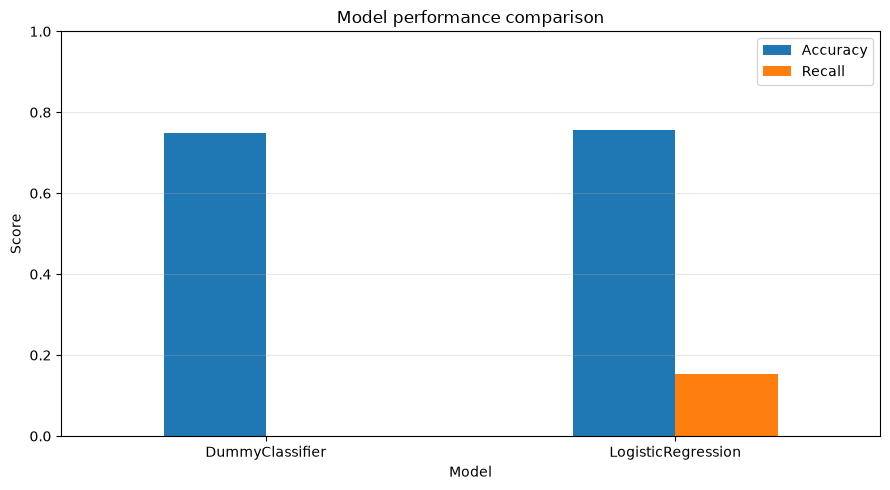

In [14]:
import matplotlib.pyplot as plt

results.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Model performance comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
feature_results = []

for feature in features:

    single_model = LogisticRegression(max_iter=3000)

    single_model.fit(X_train[[feature]], y_train)

    prediction = single_model.predict(X_val[[feature]])

    feature_results.append({
        "Feature": feature,
        "Accuracy": accuracy_score(y_val, prediction),
        "Recall": recall_score(y_val, prediction)
    })

feature_results = pd.DataFrame(feature_results)

feature_results.round(4)

,Feature,Accuracy,Recall
0,is_free,0.7495,0.0000
1,required_age,0.7518,0.0272
2,n_categories,0.7539,0.1439
3,n_genres,0.7495,0.0000
4,n_audio_languages,0.7495,0.0000


In [16]:
ablation_results = []

for feature in features:

    remaining_features = [
        f for f in features if f != feature
    ]

    reduced_model = LogisticRegression(max_iter=3000)

    reduced_model.fit(
        X_train[remaining_features],
        y_train
    )

    prediction = reduced_model.predict(
        X_val[remaining_features]
    )

    ablation_results.append({
        "Removed feature": feature,
        "Accuracy": accuracy_score(y_val, prediction),
        "Recall": recall_score(y_val, prediction)
    })

ablation_results = pd.DataFrame(ablation_results)

ablation_results.round(4)

,Removed feature,Accuracy,Recall
0,is_free,0.7553,0.1516
1,required_age,0.7550,0.1412
2,n_categories,0.7522,0.0272
3,n_genres,0.7575,0.1578
4,n_audio_languages,0.7562,0.1543


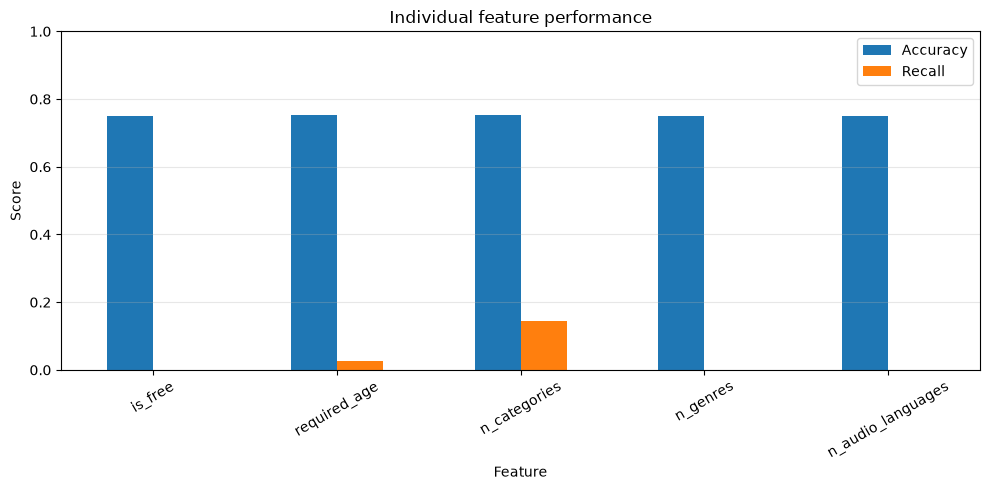

In [17]:
feature_results.set_index("Feature").plot(
    kind="bar",
    figsize=(10, 5),
    rot=30
)

plt.title("Individual feature performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_[0]
})

coefficients.sort_values(
    "Coefficient",
    ascending=False
)

,Feature,Coefficient
2,n_categories,0.203019
1,required_age,0.088978
3,n_genres,0.050798
4,n_audio_languages,-0.004176
0,is_free,-0.350208


In [19]:
print("Final model: LogisticRegression")
print("Features:", features)

print(f"Baseline accuracy: {dummy_accuracy:.4f}")
print(f"Model accuracy: {model_accuracy:.4f}")

print(f"Baseline recall: {dummy_recall:.4f}")
print(f"Model recall: {model_recall:.4f}")

print(f"Accuracy improvement: {model_accuracy - dummy_accuracy:.4f}")
print(f"Recall improvement: {model_recall - dummy_recall:.4f}")

Final model: LogisticRegression
Features: ['is_free', 'required_age', 'n_categories', 'n_genres', 'n_audio_languages']
Baseline accuracy: 0.7495
Model accuracy: 0.7561
Baseline recall: 0.0000
Model recall: 0.1533
Accuracy improvement: 0.0067
Recall improvement: 0.1533


## Motivering av valda features

Jag valde att fokusera på vilken typ av spel det är och vilken målgrupp spelet riktar sig till. Därför valde jag följande fem features:

- **is_free:** Gratis spel har möjlighet att nå en större målgrupp eftersom spelaren inte behöver betala för spelet.
- **required_age:** Åldersgränsen kan påverka hur stor målgrupp spelet har.
- **n_categories:** Antalet kategorier kan indikera hur många funktioner spelet erbjuder, exempelvis multiplayer, achievements och stöd för handkontroller.
- **n_genres:** Antalet genrer kan påverka hur många olika typer av spelare som är intresserade av spelet.
- **n_audio_languages:** Stöd för flera ljudspråk kan indikera en större produktionsbudget och möjligheten att nå en internationell målgrupp.

Jag valde dessa egenskaper eftersom de kan vara kända före lanseringen. Syftet är att undersöka om spelets funktionalitet, tillgänglighet och målgrupp har ett samband med sannolikheten att spelet blir en hit.

Jag har inte använt information som antalet recensioner, speltid, antal ägare eller utgivningsår som features, eftersom detta skulle kunna leda till dataläckage eller missvisande resultat.